# Sentiment Analysis Using Traditional Machine Learning
**PUSL 3205 – Large Language Models and Generative AI | Lab 1**

Dataset: [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences), which has 3,000 sentences from Amazon, IMDb and Yelp, each labelled positive (1) or negative (0).

## Task 1: Load the Dataset

In [40]:
import csv
import pandas as pd
import numpy as np

In [41]:
files = {
    "amazon": "../data/amazon_cells_labelled.txt",
    "imdb":   "../data/imdb_labelled.txt",
    "yelp":   "../data/yelp_labelled.txt",
}

frames = []
for source, path in files.items():
    part = pd.read_csv(
        path,
        sep="\t",
        header=None,
        names=["text", "label"],
        quoting=csv.QUOTE_NONE,  # IMDb reviews contain stray quote marks
    )
    part["source"] = source
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
df.head()

,text,label,source
0,So there is no way for me to plug it in here in the US unless I go by a converter.,0,amazon
1,"Good case, Excellent value.",1,amazon
2,Great for the jawbone.,1,amazon
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,0,amazon
4,The mic is great.,1,amazon


> **Note:** `quoting=csv.QUOTE_NONE` is required. Without it, pandas treats the `"` characters inside some IMDb reviews as quoted fields and silently loads only 748 of the 1,000 IMDb rows.

In [42]:
print("Shape:", df.shape)
print("\nRows per source:\n", df["source"].value_counts())
print("\nLabel balance:\n", df["label"].value_counts())
print("\nMissing values:\n", df.isnull().sum())

Shape: (3000, 3)

Rows per source:
 source
amazon    1000
imdb      1000
yelp      1000
Name: count, dtype: int64

Label balance:
 label
0    1500
1    1500
Name: count, dtype: int64

Missing values:
 text      0
label     0
source    0
dtype: int64


## Task 2: Text Preprocessing
Steps applied to every sentence:
1. Convert to lowercase
2. Expand negative contractions (`don't` → `do not`) so that negation survives punctuation removal
3. Remove punctuation and special characters (letters and digits are kept)
4. Remove extra whitespace

In [43]:
import re

def clean_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Expand negative contractions (irregular ones first)
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't\b", " not", text)

    # 3. Remove punctuation / special characters (keep letters, digits, spaces)
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 4. Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Quick test
clean_text("I DIDN'T like it... at ALL!!!   Won't buy again.")

'i did not like it at all will not buy again'

In [44]:
df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text", "label"]].head(10)

,text,clean_text,label
0,So there is no way for me to plug it in here in the US unless I go by a converter.,so there is no way for me to plug it in here in the us unless i go by a converter,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great for the jawbone,1
3,Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!,tied to charger for conversations lasting more than 45 minutes major problems,0
4,The mic is great.,the mic is great,1
5,I have to jiggle the plug to get it to line up right to get decent volume.,i have to jiggle the plug to get it to line up right to get decent volume,0
6,"If you have several dozen or several hundred contacts, then imagine the fun of sending each of them one by one.",if you have several dozen or several hundred contacts then imagine the fun of sending each of them one by one,0
7,If you are Razr owner...you must have this!,if you are razr owner you must have this,1
8,"Needless to say, I wasted my money.",needless to say i wasted my money,0
9,What a waste of money and time!.,what a waste of money and time,0


In [45]:
# Side-by-side examples
comparison = df[["text", "clean_text"]].sample(8, random_state=42)
pd.set_option("display.max_colwidth", None)
display(comparison)

# Before vs after statistics
stats = pd.DataFrame({
    "Original": [
        df["text"].str.len().mean(),
        df["text"].str.split().str.len().mean(),
        df["text"].str.count(r"[^\w\s]").sum(),
    ],
    "Cleaned": [
        df["clean_text"].str.len().mean(),
        df["clean_text"].str.split().str.len().mean(),
        df["clean_text"].str.count(r"[^\w\s]").sum(),
    ],
}, index=["Avg characters", "Avg words", "Total punctuation marks"])

stats.round(2)

,text,clean_text
1801,Avoid at ALL costs!,avoid at all costs
1190,"Garbo, who showed right off the bat that her talents could carry over from the silent era (I wanted to see some of her silent work, but Netflix doesn't seem to be stocking them.",garbo who showed right off the bat that her talents could carry over from the silent era i wanted to see some of her silent work but netflix does not seem to be stocking them
1817,You will leave the theater wanting to go out and dance under the stars.,you will leave the theater wanting to go out and dance under the stars
251,O my gosh the best phone I have ever had.,o my gosh the best phone i have ever had
2505,I would not recommend this place.,i would not recommend this place
1117,"Then scene where they debated whether or not to sack the trumpeter (who falsely was accused for the murder) is pure horror, really stupid.",then scene where they debated whether or not to sack the trumpeter who falsely was accused for the murder is pure horror really stupid
1411,Her role was played well.,her role was played well
2113,"Nice, spicy and tender.",nice spicy and tender


,Original,Cleaned
Avg characters,65.27,62.86
Avg words,11.83,12.13
Total punctuation marks,6465.00,0.00


### Observations
- Average sentence length dropped from ~65 to ~63 characters after cleaning.
- All punctuation was removed, while words and numbers were kept.
- Negations such as "didn't" became "did not", so the word **not** remains as a separate token.
- Numeric ratings such as "10/10" become "10 10" instead of disappearing.

## Task 3: Explore the Text Data

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_style("whitegrid")
COLORS = ["#d9534f", "#5cb85c"]  # red = negative, green = positive

In [47]:
print("POSITIVE examples:")
for t in df[df["label"] == 1]["text"].sample(5, random_state=1):
    print("  +", t.strip())

print("\nNEGATIVE examples:")
for t in df[df["label"] == 0]["text"].sample(5, random_state=1):
    print("  -", t.strip())

POSITIVE examples:
  + The file browser offers all the options that one needs.Handsfree is great.
  + My headset works just peachy-keen.
  + We enjoy their pizza and brunch.
  + Very wind-resistant.
  + Four stars for the food & the guy in the blue shirt for his great vibe & still letting us in to eat !

NEGATIVE examples:
  - Waste of 13 bucks.
  - All I can do is whine on the Internet, so here it goes.The more I use the thing the less I like it.
  - Not good for the money.
  - Bluetooth does not work, phone locks up, screens just flash up and now it just makes calls randomly while in my pocket locked.
  - Why are these sad little vegetables so overcooked?


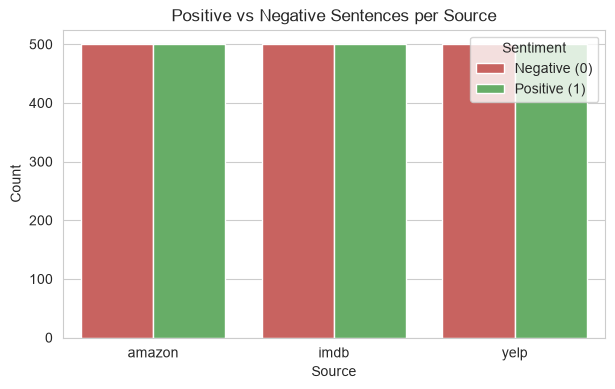

In [48]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="source", hue="label", palette=COLORS, ax=ax)
ax.set_title("Positive vs Negative Sentences per Source")
ax.set_xlabel("Source")
ax.set_ylabel("Count")
ax.legend(title="Sentiment", labels=["Negative (0)", "Positive (1)"])
plt.show()

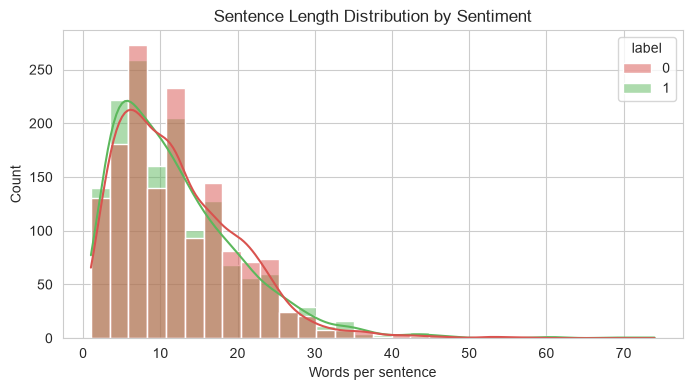

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,1500.0,12.22,7.80,1.0,6.0,11.0,17.0,57.0
1,1500.0,12.03,8.42,1.0,6.0,10.0,16.0,74.0


In [49]:
df["word_count"] = df["clean_text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="word_count", hue="label", bins=30, kde=True,
             palette=COLORS, ax=ax)
ax.set_title("Sentence Length Distribution by Sentiment")
ax.set_xlabel("Words per sentence")
plt.show()

df.groupby("label")["word_count"].describe().round(2)

In [50]:
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
negations = {"not", "no", "nor"}
stop_words = stop_words - negations   # keep negations, they carry sentiment

print(f"{len(stop_words)} stop words (negations kept: {negations})")

195 stop words (negations kept: {'nor', 'not', 'no'})


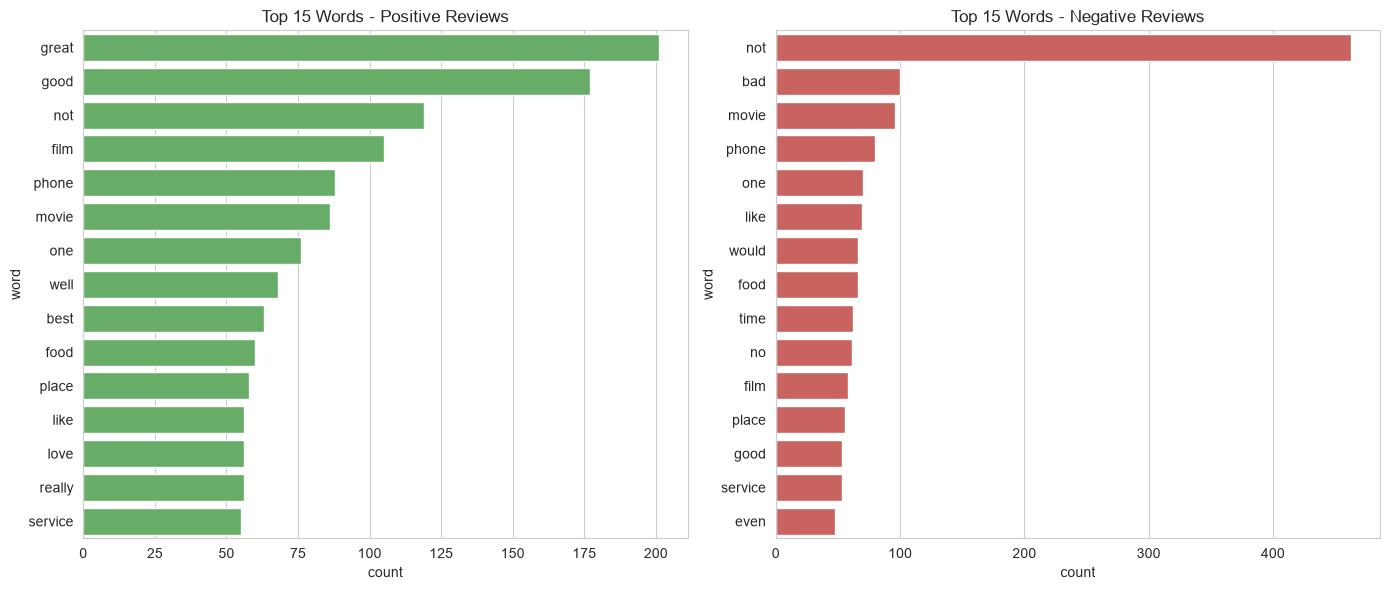

In [51]:
def get_top_words(texts, n=15):
    words = [w for t in texts for w in t.split()
             if w not in stop_words and len(w) > 1]
    return pd.DataFrame(Counter(words).most_common(n), columns=["word", "count"])

top_pos = get_top_words(df[df["label"] == 1]["clean_text"])
top_neg = get_top_words(df[df["label"] == 0]["clean_text"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_pos, x="count", y="word", color=COLORS[1], ax=axes[0])
axes[0].set_title("Top 15 Words - Positive Reviews")
sns.barplot(data=top_neg, x="count", y="word", color=COLORS[0], ax=axes[1])
axes[1].set_title("Top 15 Words - Negative Reviews")
plt.tight_layout()
plt.show()

In [52]:
pos_counts = Counter(w for t in df[df["label"] == 1]["clean_text"] for w in t.split())
neg_counts = Counter(w for t in df[df["label"] == 0]["clean_text"] for w in t.split())

check_words = ["not", "no", "never", "great", "good", "bad",
               "love", "worst", "excellent", "terrible"]

pd.DataFrame({
    "word": check_words,
    "positive": [pos_counts[w] for w in check_words],
    "negative": [neg_counts[w] for w in check_words],
}).set_index("word")

,positive,negative
word,,
not,119,463
no,22,61
never,15,37
great,201,9
good,177,53
bad,3,100
love,56,5
worst,1,39
excellent,52,1


### Observations
- **Balanced dataset:** each source has exactly 500 positive and 500 negative sentences, so accuracy is a fair metric and no resampling is needed.
- **Length does not reveal sentiment:** positive and negative sentences have almost the same average length (~12 words), so the model must rely on the words themselves.
- **Positive reviews** are dominated by words like *great, good, best, love, excellent*.
- **Negative reviews** are dominated by *not* (463 times, ~4× more than in positive reviews), followed by *bad, no, worst, terrible*.
- **"good" appears 53 times in negative reviews.** Many of these are probably phrases like "not good", which shows why keeping negations during preprocessing matters.
- Domain words (*phone, movie, film, food, place, service*) appear in both classes and carry no sentiment.

## Task 4: Split the Dataset
80% training / 20% testing. `stratify` keeps the positive/negative ratio identical in both sets.

In [53]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,   # same split every run, so results are reproducible
    stratify=y,
)

print(f"Training set: {len(X_train)} sentences")
print(f"Test set:     {len(X_test)} sentences")
print("\nTrain labels:", y_train.value_counts().to_dict())
print("Test labels: ", y_test.value_counts().to_dict())

Training set: 2400 sentences
Test set:     600 sentences

Train labels: {1: 1200, 0: 1200}
Test labels:  {1: 300, 0: 300}


## Task 5: Bag-of-Words (BoW) Representation
Each sentence becomes a vector of word counts.

The vectorizer is **fit on the training set only** and then used to transform the test set. This prevents information from the test data leaking into training.

In [54]:
from sklearn.feature_extraction.text import CountVectorizer

# Unigrams only (single words)
bow_uni = CountVectorizer()
bow_uni.fit(X_train)

# Unigrams + bigrams (single words AND word pairs)
bow = CountVectorizer(ngram_range=(1, 2))
X_train_bow = bow.fit_transform(X_train)
X_test_bow  = bow.transform(X_test)

print(f"Vocabulary size (unigrams):           {len(bow_uni.vocabulary_)}")
print(f"Vocabulary size (unigrams + bigrams): {len(bow.vocabulary_)}")
print(f"\nTrain matrix shape: {X_train_bow.shape}")
print(f"Test matrix shape:  {X_test_bow.shape}")

sparsity = 1 - X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1])
print(f"Sparsity: {sparsity:.2%} of values are zero")

Vocabulary size (unigrams):           4547
Vocabulary size (unigrams + bigrams): 21184

Train matrix shape: (2400, 21184)
Test matrix shape:  (600, 21184)
Sparsity: 99.90% of values are zero


In [55]:
example = ["the food was not good"]
vec = bow.transform(example)
features = bow.get_feature_names_out()

nonzero = sorted((features[i], vec[0, i]) for i in vec.nonzero()[1])
print(f"Sentence: {example[0]!r}")
print(f"Vector length: {vec.shape[1]}, non-zero entries: {len(nonzero)}\n")
for word, count in nonzero:
    print(f"  {word:<12} -> {count}")

print("\n'not good' in vocabulary:", "not good" in bow.vocabulary_)
print("'not bad' in vocabulary: ", "not bad" in bow.vocabulary_)

Sentence: 'the food was not good'
Vector length: 21184, non-zero entries: 9

  food         -> 1
  food was     -> 1
  good         -> 1
  not          -> 1
  not good     -> 1
  the          -> 1
  the food     -> 1
  was          -> 1
  was not      -> 1

'not good' in vocabulary: True
'not bad' in vocabulary:  True


In [56]:
example = ["the food was not good"]
vec = bow.transform(example)
features = bow.get_feature_names_out()

nonzero = sorted((features[i], vec[0, i]) for i in vec.nonzero()[1])
print(f"Sentence: {example[0]!r}")
print(f"Vector length: {vec.shape[1]}, non-zero entries: {len(nonzero)}\n")
for word, count in nonzero:
    print(f"  {word:<12} -> {count}")

print("\n'not good' in vocabulary:", "not good" in bow.vocabulary_)
print("'not bad' in vocabulary: ", "not bad" in bow.vocabulary_)

Sentence: 'the food was not good'
Vector length: 21184, non-zero entries: 9

  food         -> 1
  food was     -> 1
  good         -> 1
  not          -> 1
  not good     -> 1
  the          -> 1
  the food     -> 1
  was          -> 1
  was not      -> 1

'not good' in vocabulary: True
'not bad' in vocabulary:  True


### Why bigrams?
With unigrams only, "not good" is split into `not` + `good`, and the word *good* pushes the prediction towards positive. Adding bigrams gives the model the feature `not good` directly, so it can learn that this phrase is negative. In testing, bigrams improved accuracy by about 1–2%.

### BoW vs TF-IDF
- **BoW:** raw word counts.
- **TF-IDF:** counts weighted down for words that appear in many documents (like *the* or *was*), so rarer, more informative words get more weight.

## Task 6: Train Machine Learning Models
Three classic text classifiers, each trained on both BoW and TF-IDF features (6 combinations in total):
- **Logistic Regression**: a linear model that outputs probabilities
- **Linear SVM**: finds the boundary with the widest margin between the classes
- **Multinomial Naive Bayes**: a probabilistic model built for word counts

In [57]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
}

features = {
    "BoW":    (X_train_bow, X_test_bow, bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf, tfidf),
}

results = []
trained = {}

for feat_name, (Xtr, Xte, vectorizer) in features.items():
    for model_name, model in models.items():
        m = clone(model)              # fresh copy for each feature set
        m.fit(Xtr, y_train)
        y_pred = m.predict(Xte)

        trained[(feat_name, model_name)] = (m, vectorizer)
        results.append({
            "Features":  feat_name,
            "Model":     model_name,
            "Accuracy":  accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall":    recall_score(y_test, y_pred),
            "F1":        f1_score(y_test, y_pred),
        })

print(f"Trained {len(trained)} models.")

NameError: name 'X_train_tfidf' is not defined

## Task 7: Evaluate Model Performance
- **Accuracy**: share of all predictions that are correct
- **Precision**: of the reviews predicted *positive*, how many really are positive
- **Recall**: of the reviews that really are positive, how many the model found
- **F1**: harmonic mean of precision and recall

In [ ]:
results_df = (pd.DataFrame(results)
                .sort_values("F1", ascending=False)
                .reset_index(drop=True))
results_df.round(4)

In [ ]:
melted = results_df.melt(id_vars=["Features", "Model"],
                         value_vars=["Accuracy", "Precision", "Recall", "F1"],
                         var_name="Metric", value_name="Score")
melted["Setup"] = melted["Model"] + " (" + melted["Features"] + ")"

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=melted, x="Metric", y="Score", hue="Setup", ax=ax)
ax.set_ylim(0.75, 0.9)
ax.set_title("Model Comparison")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
best = results_df.iloc[0]
best_model, best_vectorizer = trained[(best["Features"], best["Model"])]
X_test_best = features[best["Features"]][1]
y_pred_best = best_model.predict(X_test_best)

print(f"Best model: {best['Model']} with {best['Features']}\n")
print(classification_report(y_test, y_pred_best,
                            target_names=["Negative", "Positive"], digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=["Negative", "Positive"],
    cmap="Blues", ax=ax)
ax.set_title(f"Confusion Matrix - {best['Model']} ({best['Features']})")
plt.show()

In [ ]:
lr_model, lr_vec = trained[("BoW", "Logistic Regression")]
feature_names = lr_vec.get_feature_names_out()
coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "weight": coefs})
top_features = pd.concat([coef_df.nsmallest(10, "weight"),
                          coef_df.nlargest(10, "weight")])

fig, ax = plt.subplots(figsize=(8, 6))
colors = [COLORS[0] if w < 0 else COLORS[1] for w in top_features["weight"]]
ax.barh(top_features["feature"], top_features["weight"], color=colors)
ax.set_title("Most Influential Features (Logistic Regression, BoW)")
ax.set_xlabel("Weight  (negative <- -> positive)")
plt.tight_layout()
plt.show()

In [ ]:
errors = pd.DataFrame({"text": X_test, "true": y_test, "predicted": y_pred_best})
errors = errors[errors["true"] != errors["predicted"]]
print(f"Misclassified: {len(errors)} of {len(y_test)}\n")
errors.head(10)

### Observations
- All six models perform similarly (82–85% accuracy), which is typical for traditional ML on short texts.
- **Best model: Linear SVM with TF-IDF (84.5% accuracy, F1 = 0.849).**
- Recall is higher than precision for every model, so the models lean slightly towards predicting *positive* (more false positives than false negatives).
- The most influential negative features include *bad, poor, not, worst, awful, **not good***, and the positive ones include *great, good, love, excellent, delicious*.
- Typical errors involve:
  - **Sarcasm or idioms**: "pulls no punches", "should've invented this sooner"
  - **Sentiment with no strong words**: "the camera really likes her in this movie"
  - **Unusual phrasing**: "unhappy" is not a common word in the training data

  Bag-of-words models can't capture context, which is the gap that LLMs address.